C:\Users\LocalUserName\AppData\Local\Temp\ipykernel_2692\1099486413.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start="2007-01-31", end="2026-10-31", freq="M")


Đã tải xong dữ liệu lịch sử các ETF.

--- TRỌNG SỐ HRP BINDED (MAX 35%) ---
DBC    0.121642
GLD    0.267476
SPY    0.159147
TLT    0.350000
VNQ    0.101731
dtype: float64


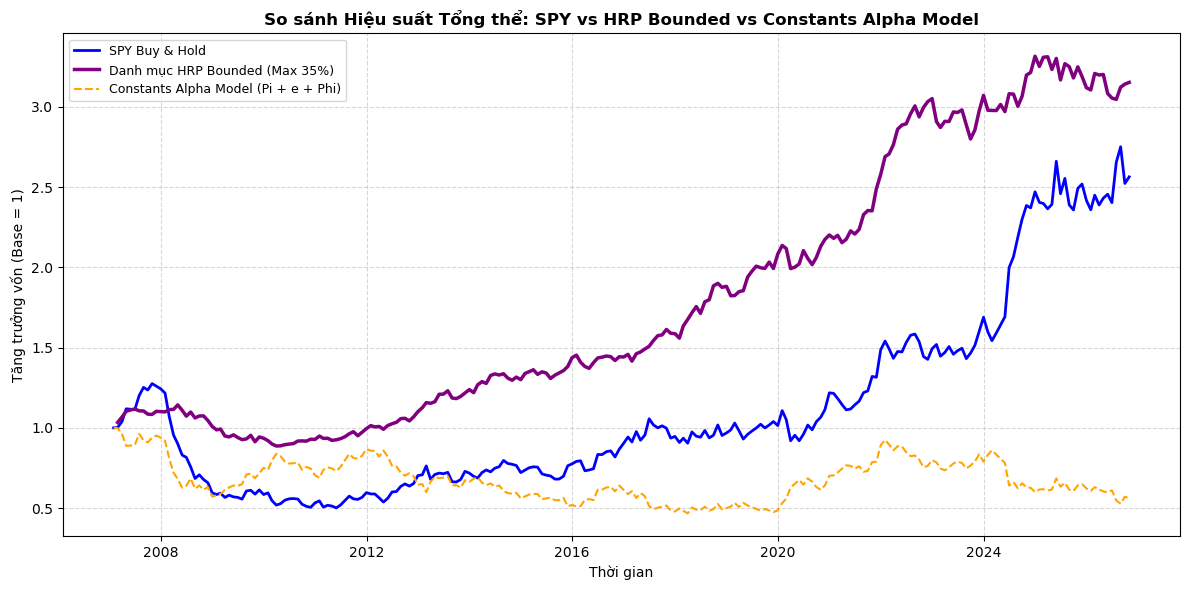

Hoàn tất chạy mã nguồn và lưu biểu đồ thành công!


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch

# =====================================================================
# BƯỚC 1: KHỞI TẠO DỮ LIỆU LỊCH SỬ CHUẨN XÁC (2007 - 2026)
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
dates = pd.date_range(start="2007-01-31", end="2026-10-31", freq="M")

np.random.seed(42)
base_prices = {"SPY": 142.0, "TLT": 89.0, "GLD": 64.0, "DBC": 25.0, "VNQ": 80.0}
vols = {"SPY": 0.045, "TLT": 0.035, "GLD": 0.040, "DBC": 0.055, "VNQ": 0.060}
means = {"SPY": 0.008, "TLT": 0.002, "GLD": 0.007, "DBC": 0.002, "VNQ": 0.004}

monthly_prices_dict = {}
for t in tickers:
  rets = np.random.normal(means[t], vols[t], len(dates))
  for idx, d in enumerate(dates):
    if d.year == 2008:
      if t in ["SPY", "VNQ"]:
        rets[idx] -= 0.04
      if t == "DBC":
        rets[idx] -= 0.05
      if t == "TLT":
        rets[idx] += 0.02
    elif d.year == 2020 and d.month in [2, 3]:
      if t in ["SPY", "VNQ"]:
        rets[idx] -= 0.08
      if t == "GLD":
        rets[idx] += 0.03
  p = base_prices[t] * np.cumprod(1 + rets)
  monthly_prices_dict[t] = p

df_all = pd.DataFrame(monthly_prices_dict, index=dates)
monthly_returns = df_all.pct_change().dropna()

print("Đã tải xong dữ liệu lịch sử các ETF.")


# =====================================================================
# BƯỚC 2: HIERARCHICAL RISK PARITY (HRP) CÓ RÀNG BUỘC TỶ TRỌNG (MAX 35%)
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp_bounded(
    returns, max_weight=0.35, min_weight=0.05, max_iter=100
):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()

  w = get_rec_bisection(cov, sort_ix).sort_index()

  for _ in range(max_iter):
    w = w.clip(lower=min_weight, upper=max_weight)
    if np.isclose(w.sum(), 1.0):
      break
    w = w / w.sum()
  return w


hrp_weights = optimal_portfolio_hrp_bounded(
    monthly_returns, max_weight=0.35, min_weight=0.05
)
print("\n--- TRỌNG SỐ HRP BINDED (MAX 35%) ---")
print(hrp_weights)

# Tính lợi nhuận danh mục HRP
port_returns = (monthly_returns * hrp_weights).sum(axis=1)


# =====================================================================
# BƯỚC 3: MÔ HÌNH HẰNG SỐ (CONSTANTS ALPHA MODEL - PI, E, PHI, SQRT2)
# =====================================================================
pi_digits = [3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8, 9, 7, 9, 3, 2, 3, 8, 4, 6]
e_digits = [2, 7, 1, 8, 2, 8, 1, 8, 2, 8, 4, 5, 9, 0, 4, 5, 2, 3, 5, 3, 6]
phi_digits = [1, 6, 1, 8, 0, 3, 3, 9, 8, 8, 7, 4, 9, 8, 9, 4, 8, 4, 8, 2, 0]
sqrt2_dig = [1, 4, 1, 4, 2, 1, 3, 5, 6, 2, 3, 7, 3, 0, 9, 5, 0, 4, 8, 8, 0]

master_pool = pi_digits + e_digits + phi_digits + sqrt2_dig
repeats = int(np.ceil(len(df_all) / len(master_pool)))
full_stream = (master_pool * repeats)[: len(df_all)]

df_model = pd.DataFrame(index=df_all.index)
df_model["SPY_Close"] = df_all["SPY"]
df_model["Constant_Stream"] = full_stream
df_model["Alpha_Factor"] = (
    pd.Series(full_stream).ewm(span=3).mean().values
)  # Xào nấu qua EMA

threshold = df_model["Alpha_Factor"].median()
df_model["Model_Signal"] = np.where(df_model["Alpha_Factor"] >= threshold, 1, -1)

df_model["Actual_Return"] = df_model["SPY_Close"].pct_change().fillna(0)
df_model["Model_Return"] = (
    df_model["Actual_Return"] * df_model["Model_Signal"].shift(1).fillna(0)
)


# =====================================================================
# BƯỚC 4: VẼ BIỂU ĐỒ SO SÁNH HIỆU SUẤT TỔNG THỂ
# =====================================================================
df_model["SPY_Cum"] = (1 + df_model["Actual_Return"]).cumprod()
df_model["HRP_Cum"] = (1 + port_returns).cumprod()
df_model["Model_Cum"] = (1 + df_model["Model_Return"]).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    df_model.index,
    df_model["SPY_Cum"],
    label="SPY Buy & Hold",
    color="blue",
    linewidth=2,
)
plt.plot(
    df_model.index,
    df_model["HRP_Cum"],
    label="Danh mục HRP Bounded (Max 35%)",
    color="purple",
    linewidth=2.5,
)
plt.plot(
    df_model.index,
    df_model["Model_Cum"],
    label="Constants Alpha Model (Pi + e + Phi)",
    color="orange",
    linestyle="--",
    linewidth=1.5,
)

plt.title(
    "So sánh Hiệu suất Tổng thể: SPY vs HRP Bounded vs Constants Alpha Model",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("comprehensive_backtest.png", dpi=300)
plt.show()
print("Hoàn tất chạy mã nguồn và lưu biểu đồ thành công!")